# Análisis exploratorio — VizWiz-Captions v1.0

Dataset de *image captioning* con fotos tomadas por personas ciegas (Gurari et al., ECCV 2020).
5 captions por imagen recogidas por crowdsourcing, con problemas de calidad reales (desenfoque,
iluminación, encuadre) y mucho texto en imagen.

Este notebook explora el dataset **ya limpio** (sin captions *precanned* ni *rejected*, vía
`wizviz_captions.py`) y contrasta con los datos crudos para medir el impacto de la limpieza.

**Índice**
1. Carga y tamaño de las particiones
2. Impacto de la limpieza (precanned / rejected)
3. Captions por imagen
4. Longitud de las captions
5. Vocabulario y captions en MAYÚSCULAS
6. Texto en la imagen (`text_detected`)
7. Problemas de calidad (metadata de crowdsourcing)
8. Ejemplos visuales
9. Conclusiones para el modelado

In [2]:
%pip install datasets pillow matplotlib pandas

  Using cached datasets-5.0.1-py3-none-any.whl.metadata (23 kB)
  Using cached huggingface_hub-1.28.0-py3-none-any.whl.metadata (16 kB)
  Using cached click-8.4.2-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.6.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
Using cached datasets-5.0.1-py3-none-any.whl (559 kB)
Using cached huggingface_hub-1.28.0-py3-none-any.whl (793 kB)
Using cached click-8.4.2-py3-none-any.whl (119 kB)
Using cached hf_xet-1.6.0-cp38-abi3-win_amd64.whl (4.0 MB)
Using cached dill-0.4.1-py3-none-any.whl (120 kB)

  Attempting uninstall: dill

    Found existing installation: dill 0.4.0

    Uninstalling dill-0.4.0:

      Successfully uninstalled dill-0.4.0

   ----------- ---------------------------- 2/7 [dill]
  Rolling back uninstall of dill
   ----------- ---------------------------- 2/7 [dill]
  Moving to c:\users\green\anaconda3\lib\site-packages\dill-0.4.0.dist-info\
   from C:\Users\green\anac

ERROR: Could not install packages due to an OSError: [Errno 2] No such file or directory: 'C:\\Users\\green\\anaconda3\\Lib\\site-packages\\dill-0.4.1.dist-info\\INSTALLERsyo48kjd.tmp'



In [3]:
%matplotlib inline
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wizviz_captions import load_wizviz_captions

ROOT = Path.cwd()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
SPLITS = ["train", "val", "test"]
print("Raíz del repo:", ROOT)

Raíz del repo: C:\Users\green\Documents\GitHub\wizviz-caption


## 1. Carga y tamaño de las particiones

Cargamos en formato *grouped* (una fila por imagen) y sin decodificar imágenes (`with_images=False`)
para que las estadísticas sean rápidas. Pasamos a `pandas` para el análisis tabular.

In [4]:
ds = load_wizviz_captions(root=ROOT, with_images=False)

# DataFrame a nivel imagen por split.
dfs = {}
for s in SPLITS:
    d = ds[s]
    dfs[s] = pd.DataFrame({
        "file_name": d["file_name"],
        "n_captions": [len(c) for c in d["captions"]],
        "captions": d["captions"],
        "text_detected": d["text_detected"],
    })

overview = pd.DataFrame({
    "imágenes": {s: len(dfs[s]) for s in SPLITS},
    "captions": {s: int(dfs[s]["n_captions"].sum()) for s in SPLITS},
    "% con texto": {s: round(100 * dfs[s]["text_detected"].mean(), 1) for s in SPLITS},
})
overview

,imágenes,captions,% con texto
train,22866,100575,64.2
val,7542,33145,66.4
test,8000,0,63.7


## 2. Impacto de la limpieza (precanned / rejected)

Comparamos los conteos crudos del JSON original con los que quedan tras filtrar las captions
*precanned* (texto fijo *"Quality issues are too severe…"*) y *rejected* (control de calidad).

       imgs_json  imgs_limpias  caps_raw  precanned  rejected  caps_limpias
split                                                                      
train      23431         22866    117155      15159      3168        100575
val         7750          7542     38750       5167       964         33145


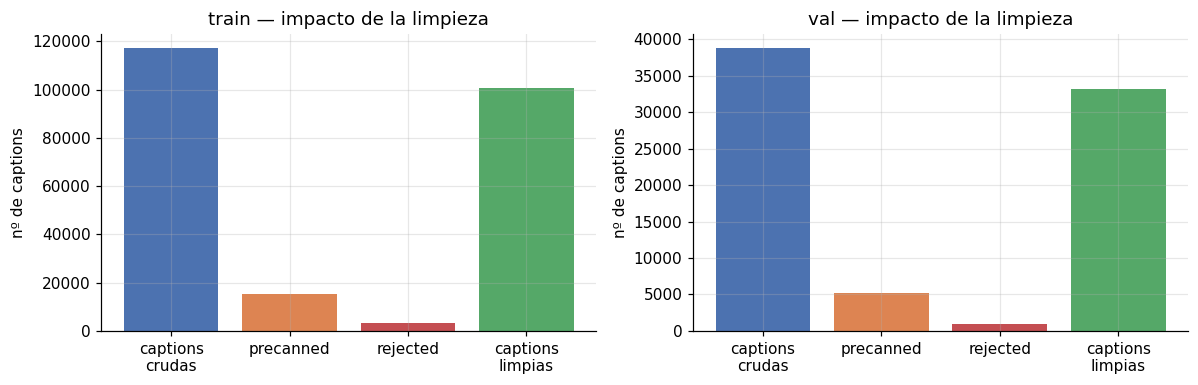

In [5]:
def raw_counts(split):
    data = json.load(open(ROOT / "annotations" / "annotations" / f"{split}.json", encoding="utf-8"))
    anns = data.get("annotations", [])
    return {
        "imgs_json": len(data["images"]),
        "caps_raw": len(anns),
        "precanned": sum(a["is_precanned"] for a in anns),
        "rejected": sum(a["is_rejected"] for a in anns),
    }

rows = []
for s in ["train", "val"]:
    r = raw_counts(s)
    r["split"] = s
    r["caps_limpias"] = int(dfs[s]["n_captions"].sum())
    r["imgs_limpias"] = len(dfs[s])
    rows.append(r)
impact = pd.DataFrame(rows).set_index("split")[
    ["imgs_json", "imgs_limpias", "caps_raw", "precanned", "rejected", "caps_limpias"]]
print(impact)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, s in zip(ax, ["train", "val"]):
    r = impact.loc[s]
    a.bar(["captions\ncrudas", "precanned", "rejected", "captions\nlimpias"],
          [r.caps_raw, r.precanned, r.rejected, r.caps_limpias],
          color=["#4C72B0", "#DD8452", "#C44E52", "#55A868"])
    a.set_title(f"{s} — impacto de la limpieza")
    a.set_ylabel("nº de captions")
fig.tight_layout()

## 3. Captions por imagen

El dataset tiene 5 captions por imagen. Tras la limpieza, algunas imágenes pierden captions
(las que eran precanned/rejected). Veamos la distribución resultante.

train: 1 caps→732 imgs, 2 caps→914 imgs, 3 caps→1655 imgs, 4 caps→4775 imgs, 5 caps→14790 imgs
val: 1 caps→274 imgs, 2 caps→286 imgs, 3 caps→547 imgs, 4 caps→1517 imgs, 5 caps→4918 imgs


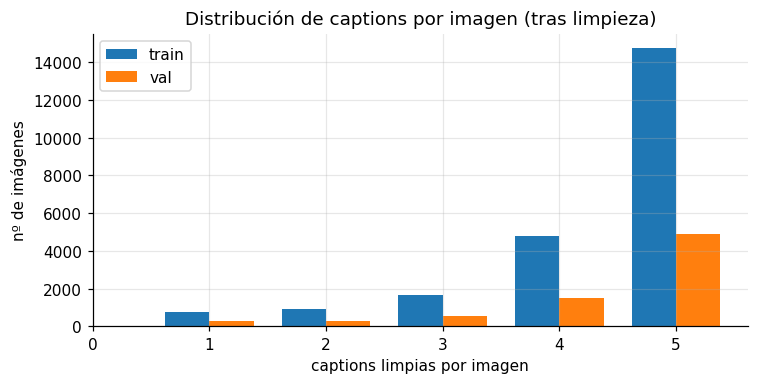

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
w = 0.38
for i, s in enumerate(["train", "val"]):
    dist = dfs[s]["n_captions"].value_counts().sort_index()
    ax.bar(dist.index + (i - 0.5) * w, dist.values, width=w, label=s)
ax.set_xlabel("captions limpias por imagen")
ax.set_ylabel("nº de imágenes")
ax.set_title("Distribución de captions por imagen (tras limpieza)")
ax.set_xticks(range(0, 6))
ax.legend()
fig.tight_layout()

for s in ["train", "val"]:
    vc = dfs[s]["n_captions"].value_counts().sort_index()
    print(f"{s}: " + ", ".join(f"{k} caps→{v} imgs" for k, v in vc.items()))

## 4. Longitud de las captions

Distribución de longitud en palabras sobre las captions limpias de train+val.

captions (train+val): 133,720
palabras — media 12.0 | mediana 11 | p5 8 | p95 20 | min 6 | max 155


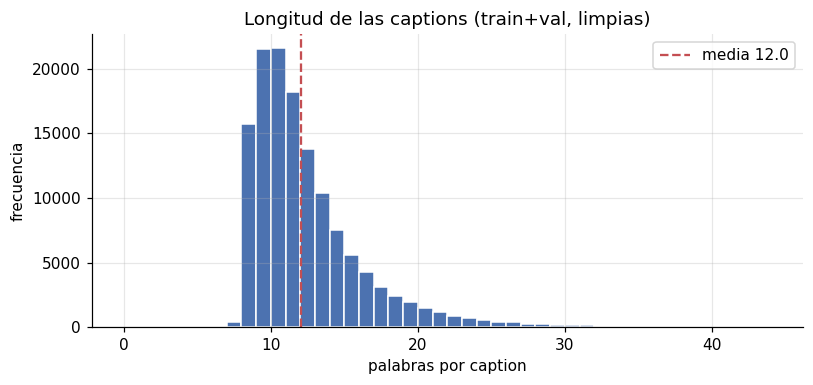

In [7]:
def all_captions(split):
    return [c for caps in dfs[split]["captions"] for c in caps]

cap_train = all_captions("train")
cap_val = all_captions("val")
len_words = np.array([len(c.split()) for c in cap_train + cap_val])

print(f"captions (train+val): {len(len_words):,}")
print(f"palabras — media {len_words.mean():.1f} | mediana {np.median(len_words):.0f} "
      f"| p5 {np.percentile(len_words,5):.0f} | p95 {np.percentile(len_words,95):.0f} "
      f"| min {len_words.min()} | max {len_words.max()}")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(len_words, bins=range(0, 45), color="#4C72B0", edgecolor="white")
ax.axvline(len_words.mean(), color="#C44E52", ls="--", label=f"media {len_words.mean():.1f}")
ax.set_xlabel("palabras por caption")
ax.set_ylabel("frecuencia")
ax.set_title("Longitud de las captions (train+val, limpias)")
ax.legend()
fig.tight_layout()

## 5. Vocabulario y captions en MAYÚSCULAS

Tokenización simple (minúsculas, `\w+`). Nota importante del dataset: bastantes captions vienen
**enteramente en MAYÚSCULAS** (a menudo transcripciones de texto de la imagen), lo que conviene
normalizar antes de entrenar.

tokens totales (train): 1,216,337 | vocabulario: 16,672 palabras únicas

captions 100% MAYÚSCULAS — train 0.8% | val 0.7%


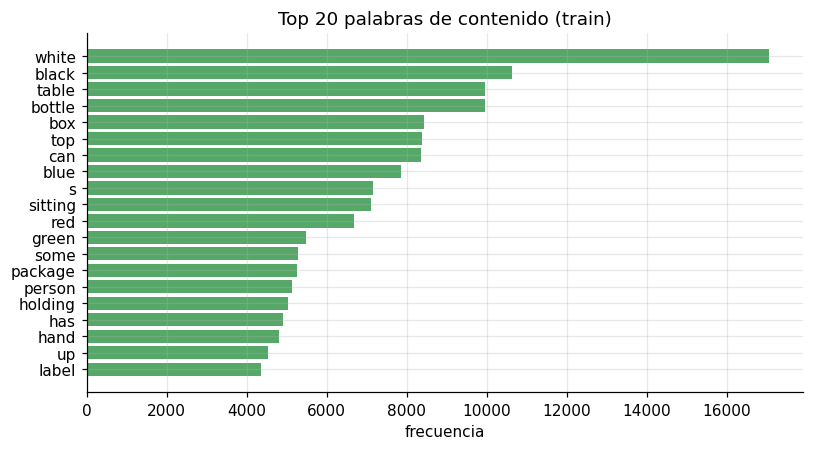

In [8]:
import re
tok = re.compile(r"[a-z]+")
counter = Counter()
for c in cap_train:
    counter.update(tok.findall(c.lower()))

total_tokens = sum(counter.values())
print(f"tokens totales (train): {total_tokens:,} | vocabulario: {len(counter):,} palabras únicas")

STOP = set("the a an of to in on is are and it this that with for at as be your you "
           "there its his her their they them from or by we".split())
top = [(w, n) for w, n in counter.most_common(200) if w not in STOP][:20]
words, freqs = zip(*top)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(words[::-1], freqs[::-1], color="#55A868")
ax.set_title("Top 20 palabras de contenido (train)")
ax.set_xlabel("frecuencia")
fig.tight_layout()

# Captions totalmente en mayúsculas.
def upper_frac(caps):
    return np.mean([c.isupper() for c in caps])
print(f"\ncaptions 100% MAYÚSCULAS — train {100*upper_frac(cap_train):.1f}% | "
      f"val {100*upper_frac(cap_val):.1f}%")

## 6. Texto en la imagen (`text_detected`)

Muchas fotos contienen texto que el usuario quería que le leyeran (etiquetas, pantallas, envases).
Esto explica por qué muchas captions son largas o transcriben texto — señal de que **OCR** puede
ayudar. ¿Las imágenes con texto tienen captions más largas?

text_detected
False    12.056076
True     11.962216
Name: mean_len, dtype: float64


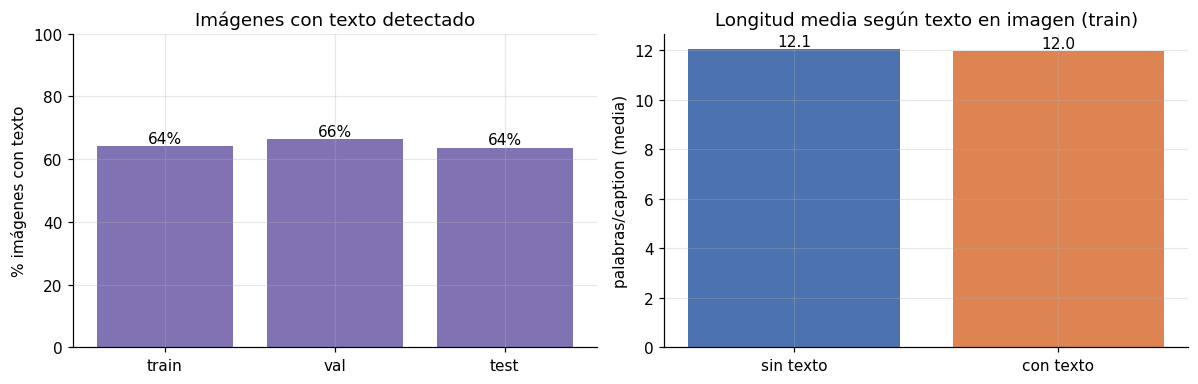

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))

# (a) proporción con texto por split
props = [dfs[s]["text_detected"].mean() * 100 for s in SPLITS]
ax[0].bar(SPLITS, props, color="#8172B3")
for i, p in enumerate(props):
    ax[0].text(i, p + 1, f"{p:.0f}%", ha="center")
ax[0].set_ylabel("% imágenes con texto")
ax[0].set_title("Imágenes con texto detectado")
ax[0].set_ylim(0, 100)

# (b) longitud media de caption según text_detected (train)
tr = dfs["train"].copy()
tr["mean_len"] = [np.mean([len(c.split()) for c in caps]) if caps else 0 for caps in tr["captions"]]
by = tr.groupby("text_detected")["mean_len"].mean()
ax[1].bar(["sin texto", "con texto"], by.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(by.values):
    ax[1].text(i, v + 0.1, f"{v:.1f}", ha="center")
ax[1].set_ylabel("palabras/caption (media)")
ax[1].set_title("Longitud media según texto en imagen (train)")
fig.tight_layout()
print(by)

## 7. Problemas de calidad (metadata de crowdsourcing)

El CSV `VizWiz_captions_project_all_metadata.csv` guarda, por anotación, qué problemas de calidad
marcó el trabajador (`Q_ISSUE_*`: BLR=blur, BRT=bright, DRK=dark, OBS=obstruction, FRM=framing,
ROT=rotation, OTH=otro, NONE=ninguno). Leemos solo esas columnas para que sea ligero.

filas de metadata (anotaciones): 195,975
encuadre       37.7
ninguno        35.5
blur           31.7
rotación       12.5
oscuro          5.9
brillo          5.4
obstrucción     4.0
otro            1.8
dtype: float64


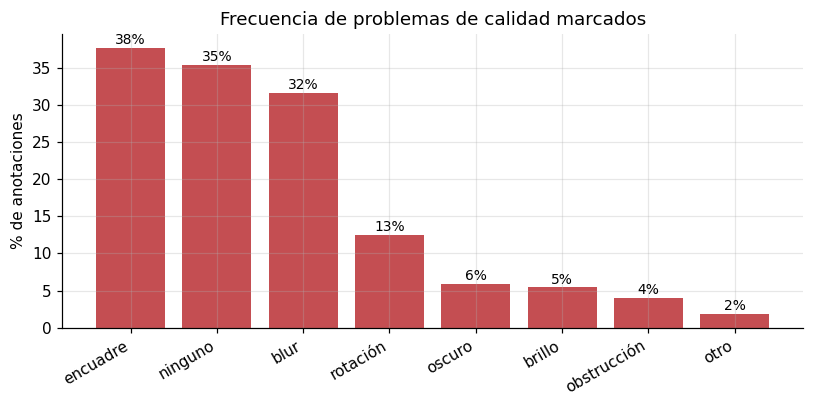

In [10]:
qcols = ["Q_ISSUE_NONE", "Q_ISSUE_BLR", "Q_ISSUE_BRT", "Q_ISSUE_DRK",
         "Q_ISSUE_OBS", "Q_ISSUE_FRM", "Q_ISSUE_ROT", "Q_ISSUE_OTH", "TRAIN_VAL_TEST"]
meta = pd.read_csv(ROOT / "VizWiz_captions_project_all_metadata.csv",
                   usecols=qcols, encoding="latin-1")
print(f"filas de metadata (anotaciones): {len(meta):,}")

labels = {"Q_ISSUE_NONE": "ninguno", "Q_ISSUE_BLR": "blur", "Q_ISSUE_BRT": "brillo",
          "Q_ISSUE_DRK": "oscuro", "Q_ISSUE_OBS": "obstrucción", "Q_ISSUE_FRM": "encuadre",
          "Q_ISSUE_ROT": "rotación", "Q_ISSUE_OTH": "otro"}
freq = (meta[list(labels)].mean() * 100).rename(labels).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(freq.index, freq.values, color="#C44E52")
for i, v in enumerate(freq.values):
    ax.text(i, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_ylabel("% de anotaciones")
ax.set_title("Frecuencia de problemas de calidad marcados")
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
print(freq.round(1))

## 8. Ejemplos visuales

Mostramos imágenes con sus captions limpias — mezclando casos con y sin texto detectado.

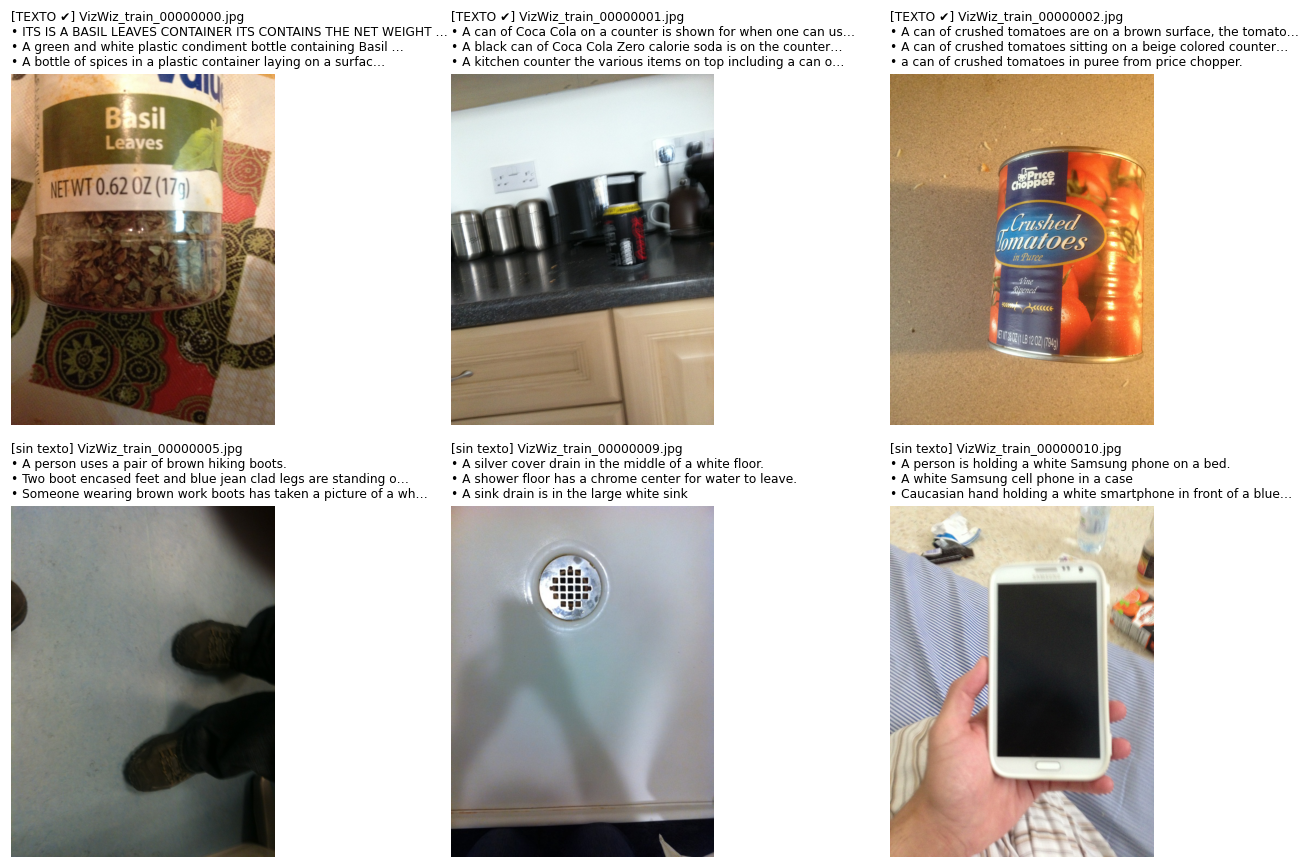

In [11]:
from PIL import Image as PILImage

sample = ds["train"].select(range(12))
# elegimos 3 con texto y 3 sin texto
with_txt = [i for i in range(12) if sample["text_detected"][i]][:3]
no_txt = [i for i in range(12) if not sample["text_detected"][i]][:3]
idxs = with_txt + no_txt

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, i in zip(axes.ravel(), idxs):
    img = PILImage.open(sample["image_path"][i]).convert("RGB")
    ax.imshow(img)
    ax.axis("off")
    caps = sample["captions"][i]
    txt = "TEXTO ✔" if sample["text_detected"][i] else "sin texto"
    cap_show = "\n".join("• " + c[:60] + ("…" if len(c) > 60 else "") for c in caps[:3])
    ax.set_title(f"[{txt}] {sample['file_name'][i]}\n{cap_show}", fontsize=8, loc="left")
fig.tight_layout()

## 9. Conclusiones para el modelado

**Preprocesado recomendado**
- Filtrar *precanned* y *rejected* (ya lo hace el loader). Quedan ~100.6k captions train / 33.1k val.
- Longitud típica ~8–12 palabras (mediana 11, p95 ≈ 20) → `max_length` de generación ~30 tokens sobra.
- Casing/ortografía: las captions 100% en MAYÚSCULAS son raras (~0.8%), así que no es un problema grande, pero sí hay ruido de mayúsculas y faltas → un *lowercasing* o *truecase* ligero antes de tokenizar no hace daño.
- Para entrenar, usar `format="exploded"` (par imagen–caption); para evaluar CIDEr/BLEU/SPICE, `format="grouped"` (5 referencias por imagen).
- Evaluación offline sobre **val** (test no tiene captions públicas).

**Sobre el dominio**
- ~63% de imágenes tienen texto detectado → un modelo con **OCR** (p. ej. inyectar el texto reconocido) o un VLM fuerte puede tener ventaja. Ojo: la longitud media de la caption es casi igual con o sin texto (~12 palabras), así que la señal está en el *contenido* (transcripción), no en captions más largas.
- Muchos problemas de calidad: **encuadre (38%)**, **blur (32%)**, y solo ~36% "sin problema" → hay imágenes genuinamente difíciles; no esperes cifras tipo COCO.

**Presupuesto de tu GPU — RTX 5060 Laptop (8 GB VRAM)**
- **Fine-tuning viable**: `ViT-GPT2` (nlpconnect) o `BLIP-base` (~250–400M params) con **LoRA/PEFT**, precisión **fp16/bf16**, `batch_size` 2–4 + *gradient accumulation*, imágenes a 224–384px. Cabe en 8 GB.
- **Ajustado/di­fícil**: BLIP-2 o modelos >1B en full fine-tuning → usar solo inferencia, o LoRA 4-bit (bitsandbytes) con batch 1.
- Empezar por **ViT-GPT2 o BLIP-base + LoRA** como baseline reproducible.
- La RTX 50xx (Blackwell, sm_120) necesita **PyTorch con CUDA 12.8+** (builds recientes / nightly); comprueba `torch.cuda.is_available()` antes de entrenar.